# 03 — Exploratory Data Analysis (EDA)

## Project: Bluestock Fintech Mutual Fund Analytics Platform

### Objective
This notebook explores mutual fund schemes, NAV history, investor transactions, SIP inflows, assets under management, portfolio holdings, and investor demographics.

### Dataset Overview
- Mutual fund schemes: 40
- NAV records: 46,000
- Investor transactions: 32,778
- Monthly SIP records: 48
- Portfolio holding records: 322

### Key Observations
- Equity schemes account for 34 of the 40 schemes in the dataset.
- Moderate-risk schemes are the most common risk category.
- SIP is the most frequent transaction type.
- The average expense ratio is higher for Equity funds than Debt funds in this dataset.
- The dataset contains both verified and pending KYC transaction records.

### Important Note
These findings describe the supplied dataset and should not be interpreted as a complete representation of the Indian mutual fund industry. Transaction counts are not unique investor counts, and transaction amounts are not equivalent to net investment inflows or profits.


In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Project root folder
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"

print("Project folder:", PROJECT_ROOT)
print("Data folder exists:", DATA_DIR.exists())
print("CSV files found:", len(list(DATA_DIR.glob("*.csv"))))

Project folder: C:\Users\asus\mutual-funds-analysis
Data folder exists: True
CSV files found: 10


In [4]:
# Load all processed CSV files
dataframes = {}

for file in DATA_DIR.glob("*.csv"):
    name = file.stem
    dataframes[name] = pd.read_csv(file)
    print(f"{name}: {dataframes[name].shape}")

print("\nTotal datasets loaded:", len(dataframes))

1788499980509-304c1255-08_investor_transactions: (32778, 13)
1788499982117-e3d6ab98-09_portfolio_holdings: (322, 8)
1788499982615-f9647ab2-10_benchmark_indices: (8050, 3)
1788499983024-b042c300-01_fund_master: (40, 15)
1788499983331-4389156d-02_nav_history: (46000, 3)
1788499984134-b0cbf625-03_aum_by_fund_house: (90, 5)
1788499984405-d702a6c6-04_monthly_sip_inflows: (48, 6)
1788499984721-4b860901-05_category_inflows: (144, 3)
1788499985036-da4a0c4a-06_industry_folio_count: (21, 6)
1788499985420-bb134abf-07_scheme_performance (1): (40, 19)

Total datasets loaded: 10


In [5]:
# Map files to simple dataset names
datasets = {}

for name, df in dataframes.items():
    if "investor_transactions" in name:
        datasets["transactions"] = df
    elif "portfolio_holdings" in name:
        datasets["holdings"] = df
    elif "benchmark_indices" in name:
        datasets["benchmarks"] = df
    elif "fund_master" in name:
        datasets["fund_master"] = df
    elif "nav_history" in name:
        datasets["nav_history"] = df
    elif "aum_by_fund_house" in name:
        datasets["aum"] = df
    elif "monthly_sip_inflows" in name:
        datasets["sip"] = df
    elif "category_inflows" in name:
        datasets["category_inflows"] = df
    elif "industry_folio_count" in name:
        datasets["folios"] = df
    elif "scheme_performance" in name:
        datasets["performance"] = df

print("Datasets ready:", list(datasets.keys()))

Datasets ready: ['transactions', 'holdings', 'benchmarks', 'fund_master', 'nav_history', 'aum', 'sip', 'category_inflows', 'folios', 'performance']


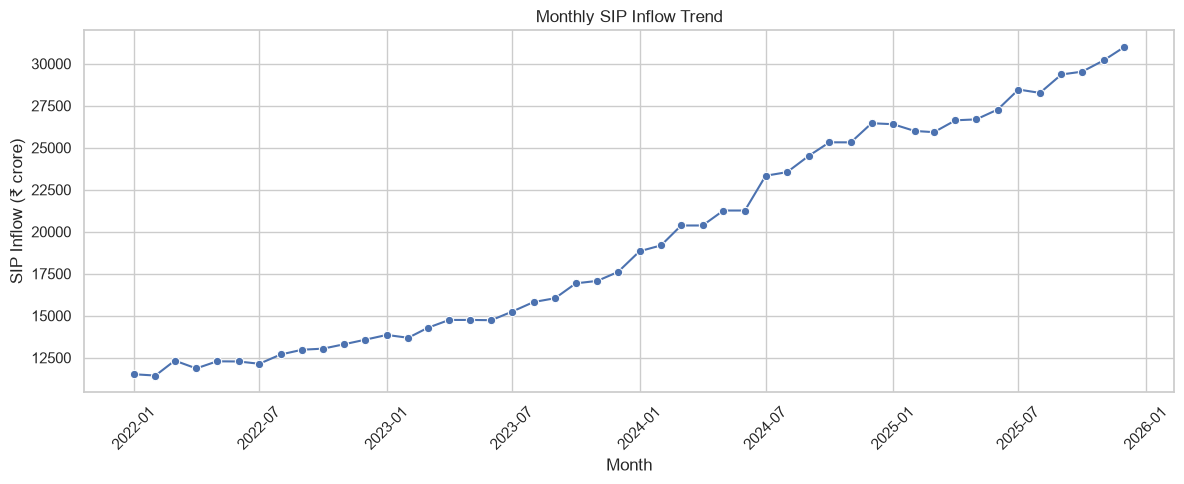

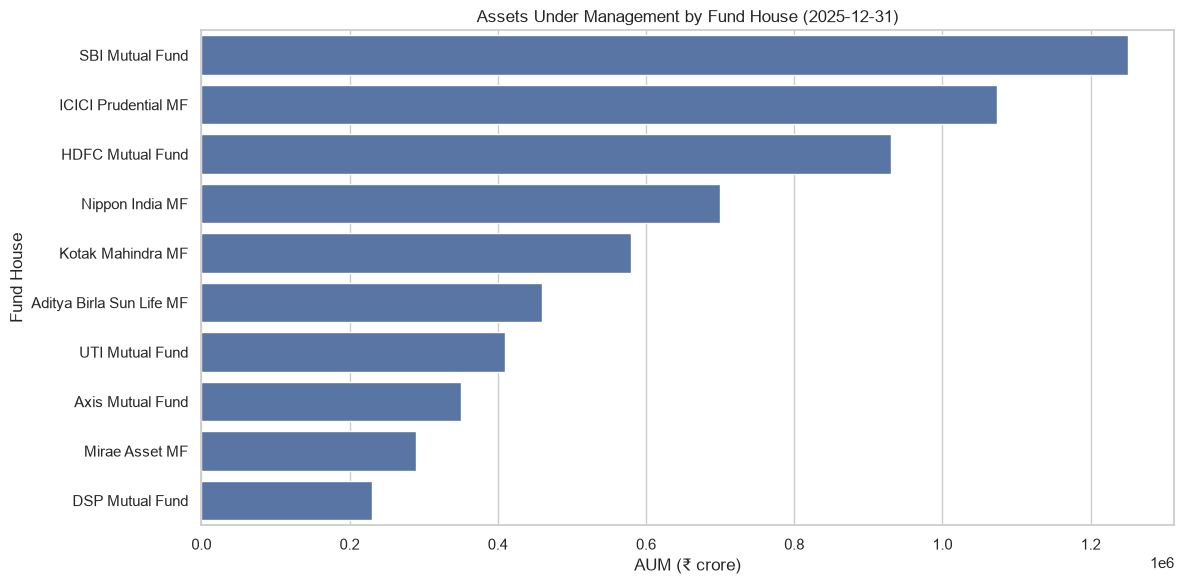

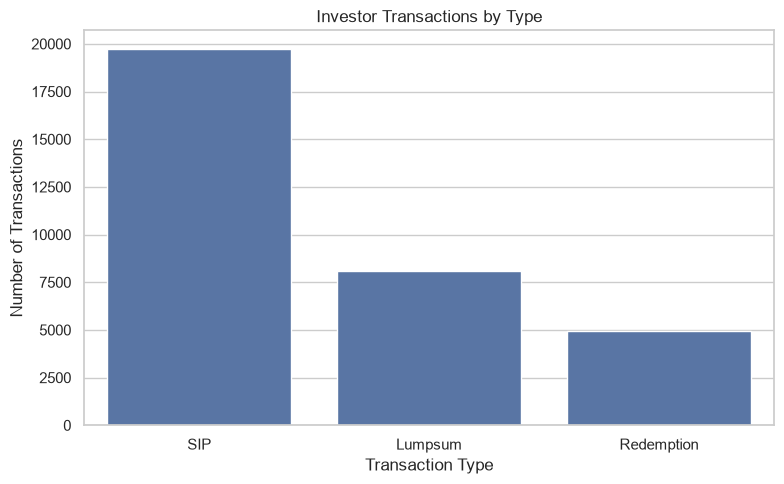

In [6]:
# Prepare plotting style
sns.set_theme(style="whitegrid", palette="deep")

# Convert date columns
datasets["sip"]["month"] = pd.to_datetime(datasets["sip"]["month"])
datasets["aum"]["date"] = pd.to_datetime(datasets["aum"]["date"])
datasets["transactions"]["transaction_date"] = pd.to_datetime(
    datasets["transactions"]["transaction_date"]
)

# 1. Monthly SIP inflow trend
plt.figure(figsize=(12, 5))
sip = datasets["sip"].sort_values("month")
sns.lineplot(data=sip, x="month", y="sip_inflow_crore", marker="o")
plt.title("Monthly SIP Inflow Trend")
plt.xlabel("Month")
plt.ylabel("SIP Inflow (₹ crore)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. Latest AUM by fund house
latest_date = datasets["aum"]["date"].max()
latest_aum = datasets["aum"][datasets["aum"]["date"] == latest_date]

plt.figure(figsize=(12, 6))
sns.barplot(
    data=latest_aum.sort_values("aum_crore", ascending=False),
    x="aum_crore",
    y="fund_house"
)
plt.title(f"Assets Under Management by Fund House ({latest_date.date()})")
plt.xlabel("AUM (₹ crore)")
plt.ylabel("Fund House")
plt.tight_layout()
plt.show()

# 3. Transaction type distribution
plt.figure(figsize=(8, 5))
transaction_counts = datasets["transactions"]["transaction_type"].value_counts()
sns.barplot(x=transaction_counts.index, y=transaction_counts.values)
plt.title("Investor Transactions by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

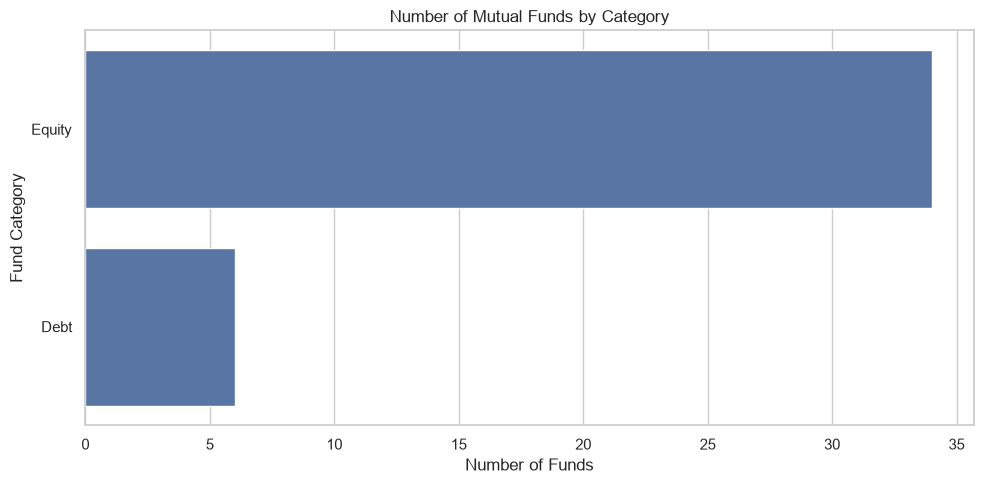

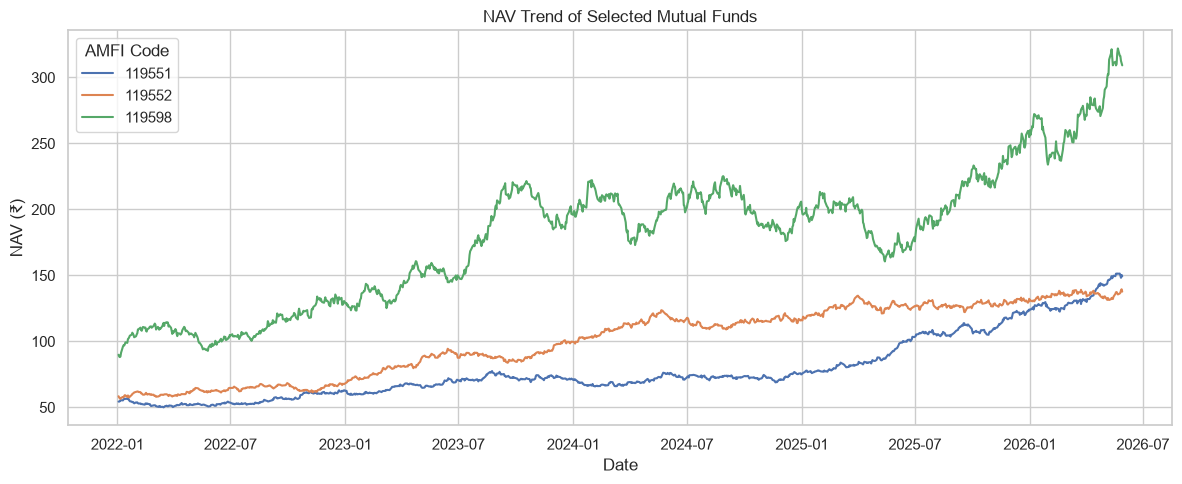

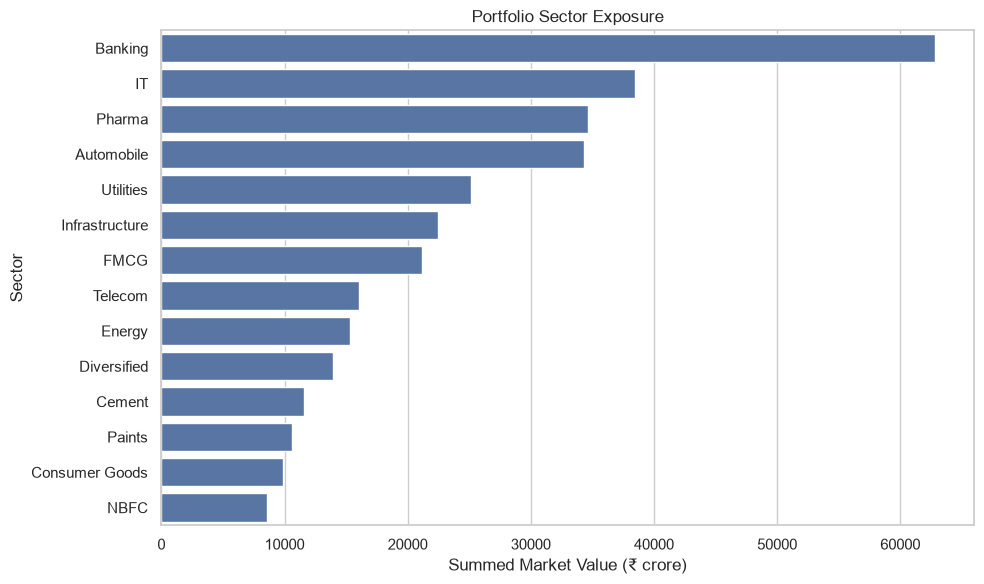

In [10]:
# 4. Fund Category Distribution
plt.figure(figsize=(10, 5))

category_counts = datasets["fund_master"]["category"].value_counts()

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Number of Mutual Funds by Category")
plt.xlabel("Number of Funds")
plt.ylabel("Fund Category")
plt.tight_layout()
plt.show()


# 5. NAV Trend of Selected Mutual Funds
nav = datasets["nav_history"].copy()
nav["date"] = pd.to_datetime(nav["date"])

# Select the first 3 schemes available in NAV data
selected_codes = nav["amfi_code"].drop_duplicates().head(3).tolist()

plt.figure(figsize=(12, 5))

for code in selected_codes:
    scheme_nav = nav[nav["amfi_code"] == code].sort_values("date")
    plt.plot(
        scheme_nav["date"],
        scheme_nav["nav"],
        label=str(code)
    )

plt.title("NAV Trend of Selected Mutual Funds")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")
plt.legend(title="AMFI Code")
plt.tight_layout()
plt.show()


# 6. Portfolio Sector Exposure
# 6. Portfolio Sector Exposure
holdings = datasets["holdings"].copy()

sector_exposure = (
    holdings.groupby("sector", as_index=False)["market_value_cr"]
    .sum()
    .sort_values("market_value_cr", ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=sector_exposure,
    x="market_value_cr",
    y="sector"
)

plt.title("Portfolio Sector Exposure")
plt.xlabel("Summed Market Value (₹ crore)")
plt.ylabel("Sector")
plt.tight_layout()
plt.show()

In [9]:
print(datasets["holdings"].columns.tolist())

['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']


In [11]:
# 7. Investor Age Group Distribution
transactions = datasets["transactions"].copy()

print(transactions.columns.tolist())

['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']


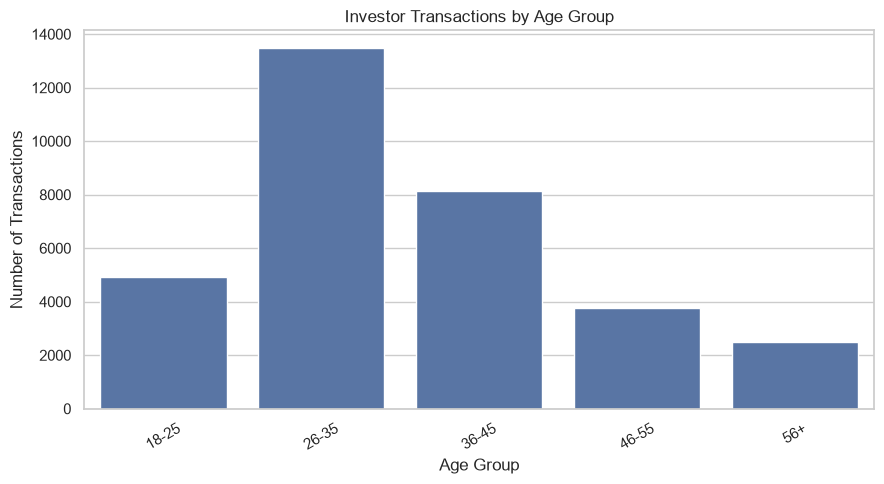

In [12]:
# 7. Investor Age Group Distribution
transactions = datasets["transactions"].copy()

age_counts = transactions["age_group"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=age_counts.index,
    y=age_counts.values
)

plt.title("Investor Transactions by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

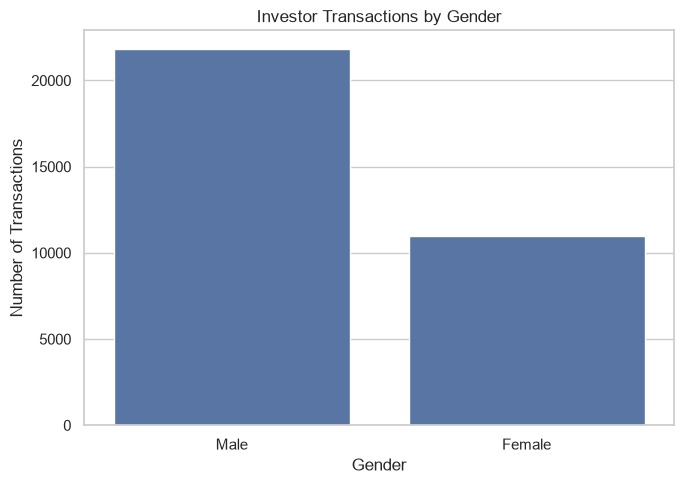

In [13]:
# 8. Investor Gender Distribution
transactions = datasets["transactions"].copy()

gender_counts = transactions["gender"].value_counts()

plt.figure(figsize=(7, 5))

sns.barplot(
    x=gender_counts.index,
    y=gender_counts.values
)

plt.title("Investor Transactions by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

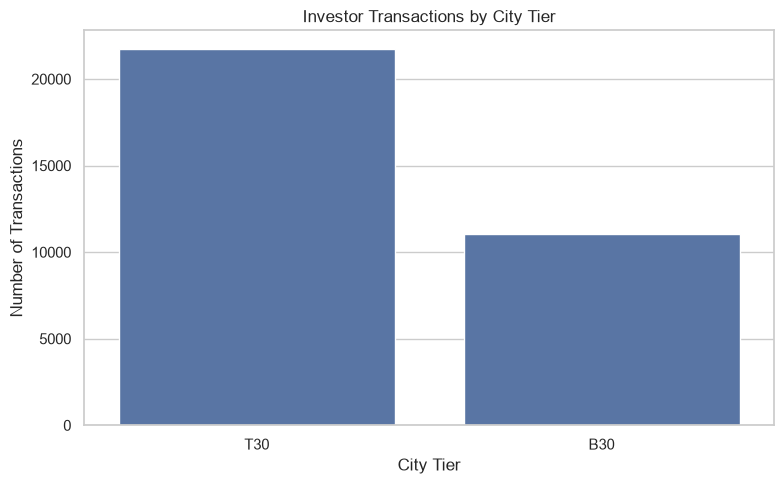

In [14]:
# 9. Transactions by City Tier
transactions = datasets["transactions"].copy()

tier_counts = transactions["city_tier"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=tier_counts.index,
    y=tier_counts.values
)

plt.title("Investor Transactions by City Tier")
plt.xlabel("City Tier")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

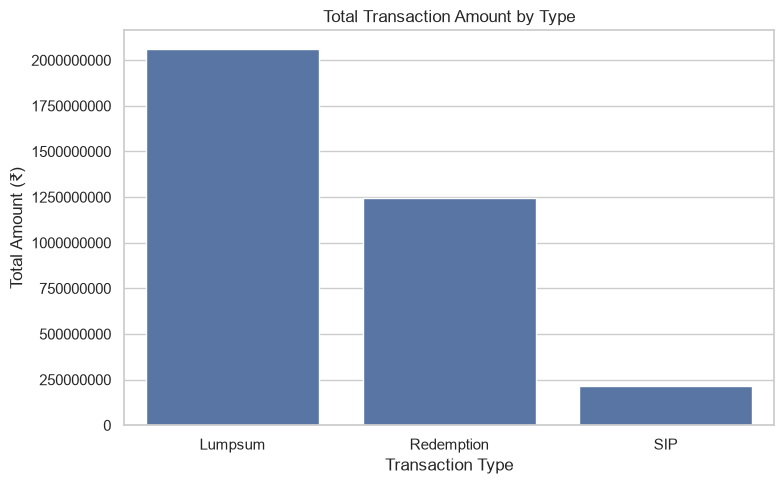

,transaction_type,amount_inr
0,Lumpsum,2059821448
1,Redemption,1244525491
2,SIP,217233491


In [15]:
# 10. Total Transaction Amount by Type
transactions = datasets["transactions"].copy()

amount_summary = (
    transactions.groupby("transaction_type", as_index=False)["amount_inr"]
    .sum()
    .sort_values("amount_inr", ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=amount_summary,
    x="transaction_type",
    y="amount_inr"
)

plt.title("Total Transaction Amount by Type")
plt.xlabel("Transaction Type")
plt.ylabel("Total Amount (₹)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

display(amount_summary)

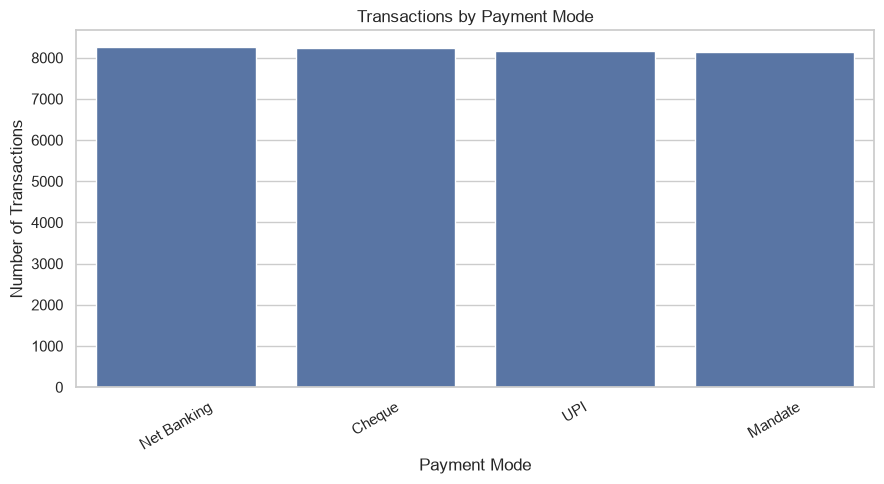

payment_mode
Net Banking    8250
Cheque         8228
UPI            8154
Mandate        8146
Name: count, dtype: int64

In [16]:
# 11. Transactions by Payment Mode
transactions = datasets["transactions"].copy()

payment_counts = transactions["payment_mode"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values
)

plt.title("Transactions by Payment Mode")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(payment_counts)

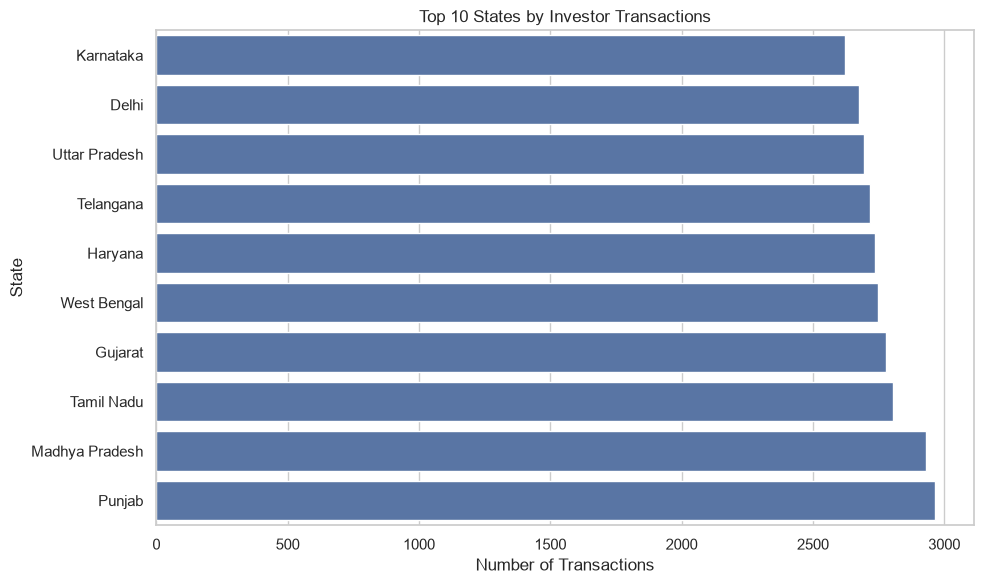

state
Punjab            2965
Madhya Pradesh    2931
Tamil Nadu        2806
Gujarat           2780
West Bengal       2748
Haryana           2736
Telangana         2718
Uttar Pradesh     2695
Delhi             2677
Karnataka         2621
Name: count, dtype: int64

In [17]:
# 12. Top 10 States by Transaction Count
transactions = datasets["transactions"].copy()

state_counts = (
    transactions["state"]
    .value_counts()
    .head(10)
    .sort_values(ascending=True)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=state_counts.values,
    y=state_counts.index
)

plt.title("Top 10 States by Investor Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("State")
plt.tight_layout()
plt.show()

display(state_counts.sort_values(ascending=False))

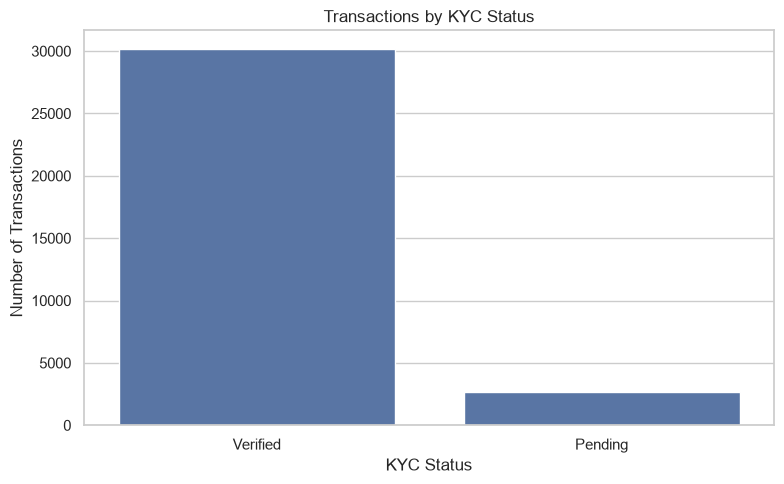

kyc_status
Verified    30146
Pending      2632
Name: count, dtype: int64

In [18]:
# 13. Transactions by KYC Status
transactions = datasets["transactions"].copy()

kyc_counts = transactions["kyc_status"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=kyc_counts.index,
    y=kyc_counts.values
)

plt.title("Transactions by KYC Status")
plt.xlabel("KYC Status")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

display(kyc_counts)

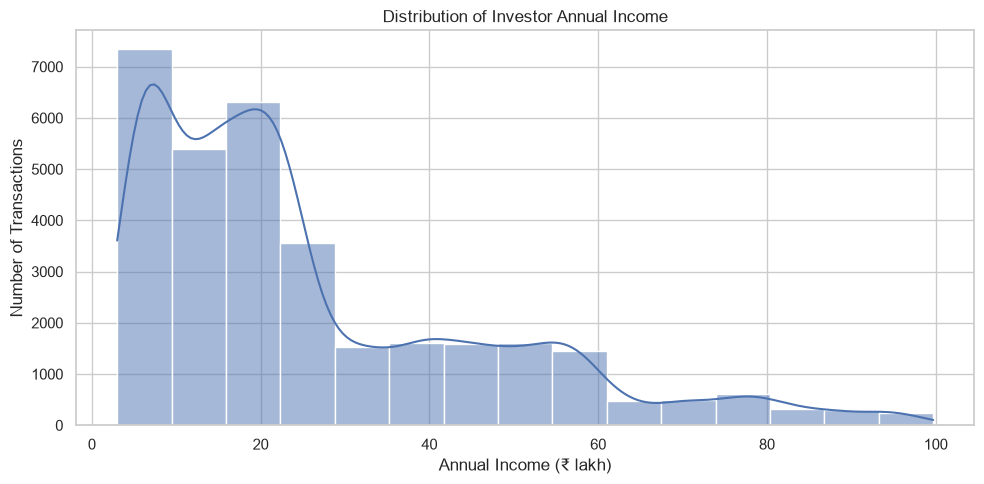

count    32778.000000
mean        26.181219
std         20.805425
min          3.000000
25%         10.600000
50%         19.700000
75%         37.400000
max         99.700000
Name: annual_income_lakh, dtype: float64

In [19]:
# 14. Transactions by Annual Income
transactions = datasets["transactions"].copy()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=transactions,
    x="annual_income_lakh",
    bins=15,
    kde=True
)

plt.title("Distribution of Investor Annual Income")
plt.xlabel("Annual Income (₹ lakh)")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

display(transactions["annual_income_lakh"].describe())

In [20]:
# Fund Category Analysis
funds = datasets["fund_master"].copy()

print(funds.columns.tolist())

['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']


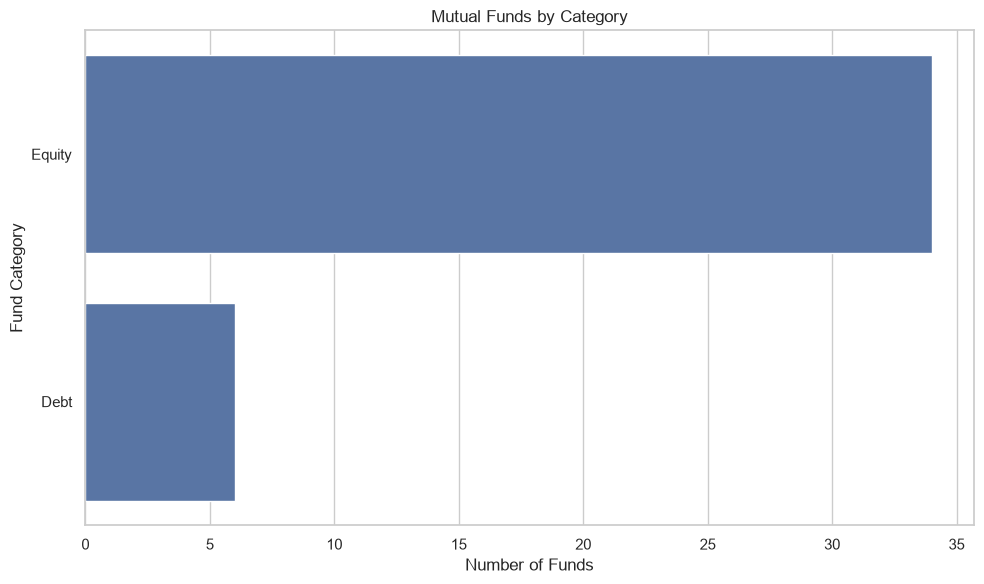

category
Equity    34
Debt       6
Name: count, dtype: int64

In [21]:
# Fund Category Distribution
funds = datasets["fund_master"].copy()

category_counts = funds["category"].value_counts()

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Mutual Funds by Category")
plt.xlabel("Number of Funds")
plt.ylabel("Fund Category")
plt.tight_layout()
plt.show()

display(category_counts)

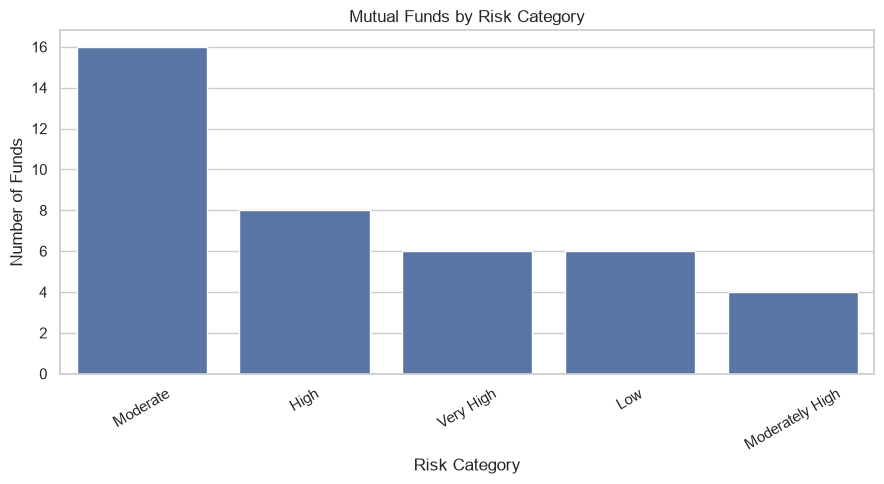

risk_category
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64

In [22]:
# Risk Category Distribution
funds = datasets["fund_master"].copy()

risk_counts = funds["risk_category"].value_counts()

plt.figure(figsize=(9, 5))

sns.barplot(
    x=risk_counts.index,
    y=risk_counts.values
)

plt.title("Mutual Funds by Risk Category")
plt.xlabel("Risk Category")
plt.ylabel("Number of Funds")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(risk_counts)

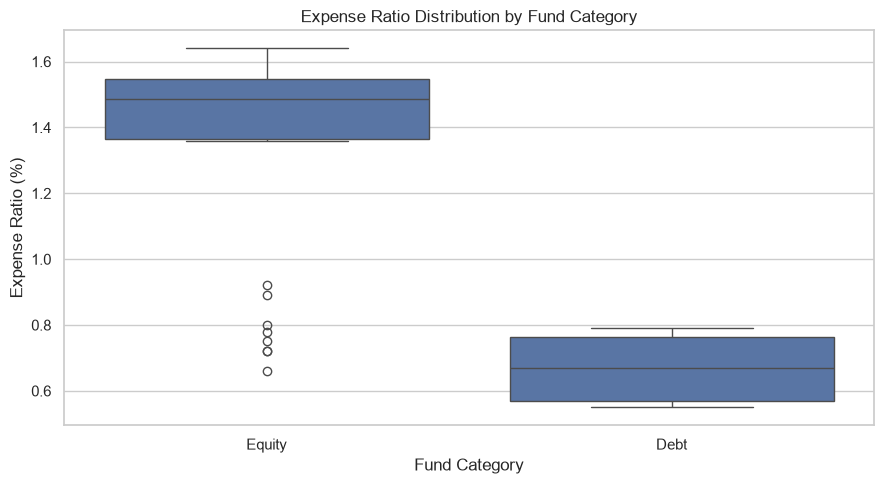

,count,mean,median,min,max
category,,,,,
Debt,6,0.668,0.670,0.55,0.79
Equity,34,1.337,1.485,0.66,1.64


In [23]:
# Expense Ratio by Fund Category
funds = datasets["fund_master"].copy()

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=funds,
    x="category",
    y="expense_ratio_pct"
)

plt.title("Expense Ratio Distribution by Fund Category")
plt.xlabel("Fund Category")
plt.ylabel("Expense Ratio (%)")
plt.tight_layout()
plt.show()

display(
    funds.groupby("category")["expense_ratio_pct"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(3)
)

In [24]:
# EDA Key Findings

print("===== EDA KEY FINDINGS =====")

print("\n1. Dataset Overview")
print("Total mutual fund schemes:", len(datasets["fund_master"]))
print("Total NAV records:", len(datasets["nav_history"]))
print("Total investor transactions:", len(datasets["transactions"]))

print("\n2. Fund Categories")
print(datasets["fund_master"]["category"].value_counts().to_string())

print("\n3. Risk Categories")
print(datasets["fund_master"]["risk_category"].value_counts().to_string())

print("\n4. Transaction Types")
print(datasets["transactions"]["transaction_type"].value_counts().to_string())

print("\n5. KYC Status")
print(datasets["transactions"]["kyc_status"].value_counts().to_string())

print("\n6. SIP Summary")
print("Total SIP inflow (₹ crore):",
      round(datasets["sip"]["sip_inflow_crore"].sum(), 2))

print("\n7. Expense Ratio by Category")
print(
    datasets["fund_master"]
    .groupby("category")["expense_ratio_pct"]
    .mean()
    .round(3)
    .to_string()
)

print("\n===== END OF SUMMARY =====")

===== EDA KEY FINDINGS =====

1. Dataset Overview
Total mutual fund schemes: 40
Total NAV records: 46000
Total investor transactions: 32778

2. Fund Categories
category
Equity    34
Debt       6

3. Risk Categories
risk_category
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4

4. Transaction Types
transaction_type
SIP           19716
Lumpsum        8095
Redemption     4967

5. KYC Status
kyc_status
Verified    30146
Pending      2632

6. SIP Summary
Total SIP inflow (₹ crore): 939721

7. Expense Ratio by Category
category
Debt      0.668
Equity    1.337

===== END OF SUMMARY =====
